# 실험 D: 점 크기를 섞어서 학습시키기

**변경점은 점 크기 분포뿐입니다.** 훈련 이미지는 총 3,200장 그대로 유지하고, 각 이미지마다 점 반지름을 2 또는 3에서 뽑습니다. 3px 검증 정확도가 개선되는지 확인하세요.

## 1. 필요한 도구 가져오기

- `numpy`: 픽셀 이미지 배열을 만들 때 사용
- `matplotlib`: 이미지, 학습 그래프 시각화
- `torch`: 신경망 학습 (PyTorch)
- `DataLoader`: 훈련 이미지를 여러 개씩 나눠서 모델에 전달

Colab 기본 환경에 보통 설치되어 있으므로 별도 설치 명령 없이 시작한다. `ModuleNotFoundError`가 나는 경우에만 해당 라이브러리 설치를 확인한다.

In [12]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 작은 프로젝트라 CPU를 사용한다. GPU 설정은 필요하지 않다.
device = torch.device("cpu")

print("PyTorch 버전:", torch.__version__)
print("사용 장치:", device)


PyTorch 버전: 2.11.0+cpu
사용 장치: cpu


## 2. 한 장의 점 이미지 만드는 함수

컴퓨터가 읽을 이미지 크기는 **32×32 = 총 1,024개 픽셀**이다.

- 픽셀값 `0`: 검은색
- 픽셀값 `1`: 흰색
- 점의 중심은 4×4 격자의 16개 자리 중 서로 다른 자리를 무작위로 선택한다.
- 각 중심에 ±1픽셀 작은 흔들림을 준다.

점끼리 심하게 겹치거나 이미지 밖으로 나가지 않도록 설계했다. 완전히 무작위 위치에 점을 놓는 것보다 쉬운 문제라는 한계가 있다.

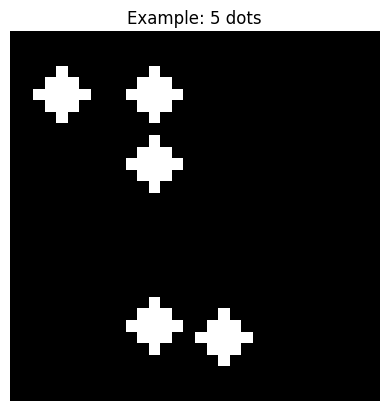

이미지 크기: (32, 32)
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [13]:
IMAGE_SIZE = 32
DOT_COUNTS = range(1, 9)  # 정답은 1~8개 중 하나

# 이미지의 16개 점 배치 후보 위치 (x, y)
POSITIONS = [(x, y) for y in [5, 12, 19, 26] for x in [5, 12, 19, 26]]
YY, XX = np.ogrid[:IMAGE_SIZE, :IMAGE_SIZE]

def make_dot_image(dot_count, radius=2):
    """지정한 개수의 점이 있는 흑백 이미지를 만든다."""
    if not 1 <= dot_count <= 8:
        raise ValueError("dot_count는 1~8 사이여야 합니다.")
    image = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.float32)
    selected = np.random.choice(len(POSITIONS), size=dot_count, replace=False)

    for index in selected:
        x, y = POSITIONS[index]
        x += np.random.randint(-1, 2)  # -1, 0, 1 중 하나
        y += np.random.randint(-1, 2)
        dot_mask = (XX - x) ** 2 + (YY - y) ** 2 <= radius ** 2
        image[dot_mask] = 1.0
    return image

# 5개 점이 들어 있는 예시 이미지 1장
sample_image = make_dot_image(5)
plt.imshow(sample_image, cmap="gray", vmin=0, vmax=1)
plt.title("Example: 5 dots")
plt.axis("off")
plt.show()
print("이미지 크기:", sample_image.shape)
print(sample_image)


## 3. 학습용 / 시험용 데이터셋 생성하기

- **훈련용(train)**: 각 개수당 2px·3px 혼합하여 400장 → 총 3,200장
- **시험용(test)**: 각 개수당 100장 → 총 800장
- 매번 점 배치가 새로 생성되므로 훈련 이미지와 시험 이미지는 별도로 만든다.
- 사람이 보는 정답 `1개 ~ 8개`를 컴퓨터 내부에는 `0 ~ 7`의 **클래스 번호**로 저장한다.

> "새로운 점 크기도 잘 맞힐까?"

In [14]:
def create_dataset(images_per_class, radius=2, mixed_radius=False):
    images = []
    labels = []

    for dot_count in DOT_COUNTS:
        for _ in range(images_per_class):
            if mixed_radius:
                image_radius = np.random.choice([2, 3])
            else:
                image_radius = radius

            images.append(make_dot_image(dot_count, radius=image_radius))
            labels.append(dot_count - 1)  # 점 1개 → 라벨 0, 점 8개 → 라벨 7

    # 클래스 순서대로 쌓지 않고 전체를 섞는다.
    order = np.random.permutation(len(labels))
    images_array = np.array(images, dtype=np.float32)[order]
    labels_array = np.array(labels, dtype=np.int64)[order]

    # (장수, 1, 32, 32) 모양: 1은 흑백 채널 한 개를 의미한다.
    images_tensor = torch.tensor(images_array).unsqueeze(1)
    labels_tensor = torch.tensor(labels_array, dtype=torch.long)
    return images_tensor, labels_tensor

X_train, y_train = create_dataset(400, mixed_radius=True)
np.random.seed(2026)
X_test, y_test = create_dataset(100, radius=2)

print("훈련 이미지:", X_train.shape)
print("훈련 정답:", y_train.shape)
print("시험 이미지:", X_test.shape)
print("시험 정답:", y_test.shape)


훈련 이미지: torch.Size([3200, 1, 32, 32])
훈련 정답: torch.Size([3200])
시험 이미지: torch.Size([800, 1, 32, 32])
시험 정답: torch.Size([800])


## 4. 실제 훈련 이미지를 눈으로 확인하기

각 그림의 제목은 진짜 점의 개수다. 이미지가 예상대로 생성되었는지 먼저 확인한다.

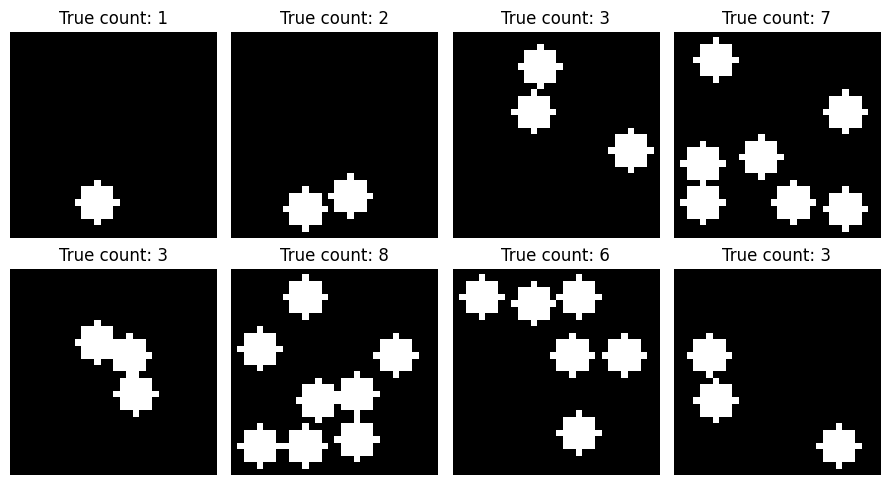

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(9, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True count: {y_train[i].item() + 1}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. 신경망 모델 정의하기

**MLP(다층 퍼셉트론)**을 사용한다.

1. `Flatten`: 32×32의 픽셀을 길이 1,024짜리 숫자 목록으로 펼친다.
2. `Linear(1024,128)`: 입력 1,024개 → 특징 128개
3. `ReLU`: 음수 값을 0으로 바꾸는 활성화 함수
4. `Linear(128,64)`: 특징 128개 → 64개
5. `Linear(64,8)`: **8개 정답 후보(점 1~8개)**에 대한 점수 출력

마지막 점수는 확률이 아닌 **로짓(logit)** 이다. `CrossEntropyLoss`가 내부적으로 적절히 처리해 주기 때문에 마지막에 직접 Softmax를 넣지 않는다.

In [16]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(32 * 32, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 8),
).to(device)

print(model)

# 한 장을 넣으면 8개 클래스 점수가 나온다.
with torch.no_grad():
    example_scores = model(X_train[:1].to(device))
print("한 이미지에 대한 출력 크기:", example_scores.shape)


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=1024, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=8, bias=True)
)
한 이미지에 대한 출력 크기: torch.Size([1, 8])


## 6. 학습 준비: 배치·손실함수·최적화 도구

- `batch_size=64`: 한 번에 이미지 64장을 보고 학습
- `CrossEntropyLoss`: 정답 클래스와 예측 점수 차이를 계산
- `Adam`: 모델 가중치를 조금씩 업데이트
- `lr=0.001`: 업데이트 크기(학습률)
- `EPOCHS=15`: 전체 훈련 데이터를 총 15번 반복해서 학습

In [17]:
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 15

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("배치 개수:", len(train_loader))


배치 개수: 50


## 7. 실제 모델 학습하기

핵심 학습 순서는 다음과 같다.

`예측 → 손실 계산 → 기존 기울기 초기화 → 역전파 → 모델 가중치 업데이트`

- `model.train()`: 훈련 모드
- `optimizer.zero_grad()`: 이전 기울기 초기화
- `loss.backward()`: 역전파로 기울기 계산
- `optimizer.step()`: 가중치 업데이트
- `model.eval()` + `torch.no_grad()`: 평가 모드에서 가중치를 바꾸지 않고 시험

학습이 진행되면 `Epoch 01`부터 `Epoch 15`까지 출력된다.

In [18]:
train_losses = []
test_accuracies = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        predictions = model(images)        # (64, 8) 점수
        loss = loss_fn(predictions, labels) # 정답과 비교

        optimizer.zero_grad()  # 이전 기울기 지우기
        loss.backward()        # 기울기 계산하기
        optimizer.step()       # 가중치 바꾸기

        total_loss += loss.item() * len(images)

    avg_loss = total_loss / len(X_train)
    train_losses.append(avg_loss)

    model.eval()
    with torch.no_grad():
        test_scores = model(X_test.to(device))
        test_predictions = test_scores.argmax(dim=1).cpu()
        test_accuracy = (test_predictions == y_test).float().mean().item()
        test_accuracies.append(test_accuracy)

    print(f"Epoch {epoch + 1:02d}/{EPOCHS} | "
          f"Train loss: {avg_loss:.4f} | Test accuracy: {test_accuracy * 100:.1f}%")

print(f"\n최종 시험 정확도: {test_accuracies[-1] * 100:.1f}%")


Epoch 01/15 | Train loss: 1.9392 | Test accuracy: 29.8%
Epoch 02/15 | Train loss: 1.4492 | Test accuracy: 56.1%
Epoch 03/15 | Train loss: 0.9183 | Test accuracy: 70.9%
Epoch 04/15 | Train loss: 0.6197 | Test accuracy: 83.2%
Epoch 05/15 | Train loss: 0.4202 | Test accuracy: 85.5%
Epoch 06/15 | Train loss: 0.2914 | Test accuracy: 90.5%
Epoch 07/15 | Train loss: 0.2022 | Test accuracy: 90.5%
Epoch 08/15 | Train loss: 0.1391 | Test accuracy: 93.4%
Epoch 09/15 | Train loss: 0.1003 | Test accuracy: 91.6%
Epoch 10/15 | Train loss: 0.0785 | Test accuracy: 92.9%
Epoch 11/15 | Train loss: 0.0570 | Test accuracy: 92.3%
Epoch 12/15 | Train loss: 0.0427 | Test accuracy: 92.3%
Epoch 13/15 | Train loss: 0.0334 | Test accuracy: 92.6%
Epoch 14/15 | Train loss: 0.0270 | Test accuracy: 92.6%
Epoch 15/15 | Train loss: 0.0219 | Test accuracy: 92.6%

최종 시험 정확도: 92.6%


## 8. 학습 과정 그래프로 보기

- **Loss가 감소**: 훈련 데이터에 대한 오차가 줄어드는 경향
- **Test accuracy가 증가**: 처음 보거나 학습에 쓰지 않은 새 이미지도 더 잘 분류하는 경향
- 반드시 매번 정확도가 오르지는 않는다. 값이 흔들리는 것은 정상이다.
- 시험 점수를 보면서 설정을 반복 변경하는 것은 엄밀한 최종 성능 검증 방식은 아니다. 별도의 검증용 데이터셋이 추가로 필요하다.

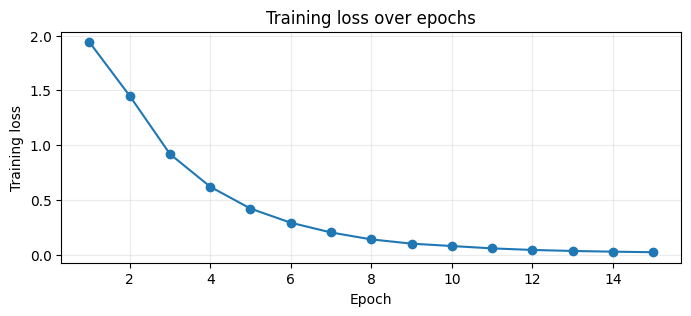

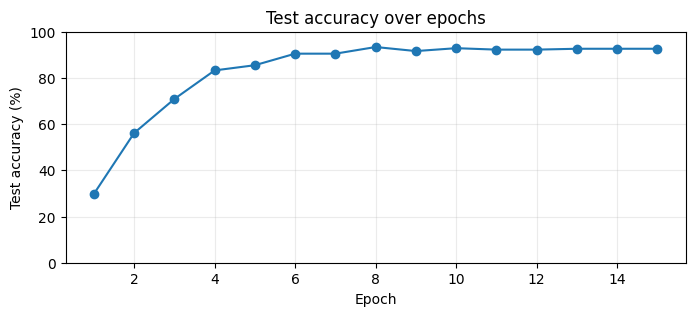

In [19]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 3))
plt.plot(epochs, train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss over epochs")
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(epochs, [x * 100 for x in test_accuracies], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Test accuracy (%)")
plt.title("Test accuracy over epochs")
plt.ylim(0, 100)
plt.grid(alpha=0.25)
plt.show()


## 9. 모델의 실제 예측 결과 확인하기

여기에 표시된 `True`는 실제 점 개수, `Pred`는 모델의 예측 개수다. 제목에 정답 여부도 표시한다.

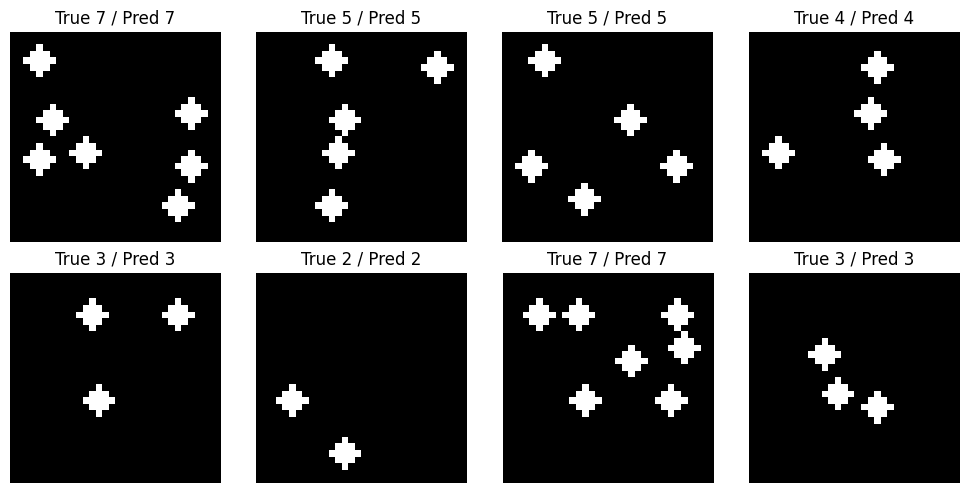

In [20]:
model.eval()
with torch.no_grad():
    all_preds = model(X_test.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    true_count = y_test[i].item() + 1
    predicted_count = all_preds[i].item() + 1
    ax.imshow(X_test[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True {true_count} / Pred {predicted_count}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. 개수별로 얼마나 잘 맞히는지 확인하기

전체 정확도가 높아도 어떤 개수(예: 7, 8)를 유난히 못 맞힐 수 있다. 각 개수의 정확도를 따로 살펴본다.

In [21]:
print("점 개수별 정답률")
for count in DOT_COUNTS:
    mask = y_test == (count - 1)
    accuracy = (all_preds[mask] == y_test[mask]).float().mean().item()
    print(f"{count}개: {accuracy * 100:.1f}%")


점 개수별 정답률
1개: 100.0%
2개: 100.0%
3개: 100.0%
4개: 96.0%
5개: 91.0%
6개: 93.0%
7개: 97.0%
8개: 64.0%


## 11. 작은 연구 질문: 점 크기가 달라지면?

**가설 예시**: '점의 크기가 커지면, 고정된 크기의 점으로만 학습한 모델의 예측 정확도가 달라질 것이다.'

학습은 반지름 2픽셀로만 했고, 이번에는 **반지름 3픽셀**인 이미지를 **새로 만들어** 평가한다. 학습된 모델은 추가 학습하지 않는다.

⚠️ 이 비교에서는 **점 크기뿐 아니라 전체 흰색 픽셀 면적도 변한다**. 따라서 결과만으로 사람의 수량 감각이나 뇌의 인지 원리를 입증할 수 없다. 단순한 강건성(robustness) 입문 실험이다.

기본 점 반지름 2px: 92.6%
더 큰 점 반지름 3px: 90.0%


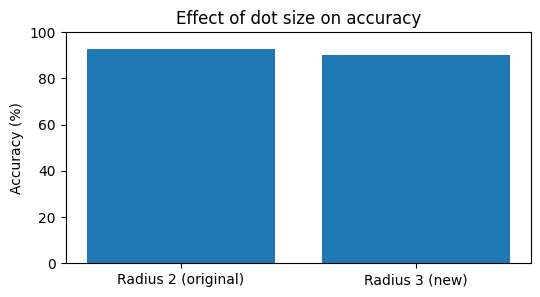

In [22]:
np.random.seed(2027)
X_bigger, y_bigger = create_dataset(100, radius=3)

model.eval()
with torch.no_grad():
    bigger_preds = model(X_bigger.to(device)).argmax(dim=1).cpu()
    bigger_accuracy = (bigger_preds == y_bigger).float().mean().item()

original_accuracy = (all_preds == y_test).float().mean().item()
print(f"기본 점 반지름 2px: {original_accuracy * 100:.1f}%")
print(f"더 큰 점 반지름 3px: {bigger_accuracy * 100:.1f}%")

plt.figure(figsize=(6, 3))
plt.bar(["Radius 2 (original)", "Radius 3 (new)"],
        [original_accuracy * 100, bigger_accuracy * 100])
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Effect of dot size on accuracy")
plt.show()
